# Univariate Analysis

## 1. Setup and Data Overview

This notebook analyses each attribute of the order dataset using univariate methods. The table below summarises all numerical attributes.

In [1]:
# Download the necessary libraries
import pandas as pd
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt

# Load the data
clean_data = pd.read_excel("customers_sales_with_dxf_data.xlsx")
clean_data.head(5)

,customer_name,customer_branch,file_name,order_quantity,customer_name_original,customer_branch_original,bounding_box_width,bounding_box_height,bounding_box_area,cutting_length,num_holes,rectangularity,pierce_dens_per_1m,circle_dens_percent,corner_dens_per_1m
0,MetalForm SA,Frankfurt Branch,Geo (1).DXF,1600,MetalForm SA,Frankfurt Branch,1600.219048,305.140135,488291.056038,3438.024977,0,0.082199,0.290865,0.000000,1.163459
1,AutoParts AG,Munich Branch,Geo (10).DXF,9650,AutoParts AG,Munich Branch,853.830000,333.401400,284668.117362,3217.207505,5,0.724271,1.864971,0.000000,1.864971
2,PrecisionCut GmbH,Stuttgart Branch,Geo (11).DXF,7800,PrecisionCut GmbH,Stuttgart Branch,164.000000,145.120000,23799.680000,1742.517642,7,0.600032,4.591058,1.081743,2.295529
3,PrecisionCut GmbH,Stuttgart Branch,Geo (15).DXF,4000,PrecisionCut GmbH,Stuttgart Branch,193.800891,138.442589,26830.297074,1302.774283,2,0.685885,2.302778,0.000000,40.682412
4,AutoParts AG,Berlin Branch,Geo (12).DXF,8800,AutoParts AG,Berlin Branch,937.150697,74.006665,69355.398059,2764.783512,11,0.865878,4.340304,0.000000,3.616920


In [2]:
print(clean_data.describe())
print(clean_data.shape)

       order_quantity  bounding_box_width  bounding_box_height  \
count       75.000000           75.000000            75.000000   
mean      7630.666667          678.352528           246.674270   
std       4794.189144          572.374302           288.009826   
min        500.000000           31.495106            12.109000   
25%       4000.000000          173.262228            70.313000   
50%       7650.000000          454.029112           131.505377   
75%       9050.000000         1150.193570           312.833986   
max      19700.000000         1968.901094          1193.261380   

       bounding_box_area  cutting_length   num_holes  rectangularity  \
count       7.500000e+01       75.000000   75.000000       75.000000   
mean        2.666915e+05     3046.694269    9.426667        0.687467   
std         4.871658e+05     3930.623051   25.990733        0.241032   
min         3.813742e+02      100.961326    0.000000        0.082199   
25%         1.505401e+04      775.298742    0

The dataset contains 75 rows with no missing values in any numerical column. Note that the attributes live on very different scales. In the following each attribute is alasysed further.

## 2. Categorical Attributes

### 2.1 Customers

This section counts how many orders each customer placed and what share of all orders this represents. Eventhough it is not technically univariate, it also shows the share of ordered *pieces*, because customers with many small orders and customers with few large orders differ. The order volume is distributed unevenly across the customers.

        customer_name  number_of_orders  share_of_orders  total_quantity  \
0        AutoParts AG                32        42.666667          268850   
1        MetalForm SA                13        17.333333           17300   
2   PrecisionCut GmbH                19        25.333333          102150   
3  TechFab Industries                11        14.666667          184000   

   share_of_quantity  
0           46.97711  
1            3.02289  
2           17.84903  
3           32.15097  

sum of orders:  75
highest number of orders:  32 by customer:  AutoParts AG


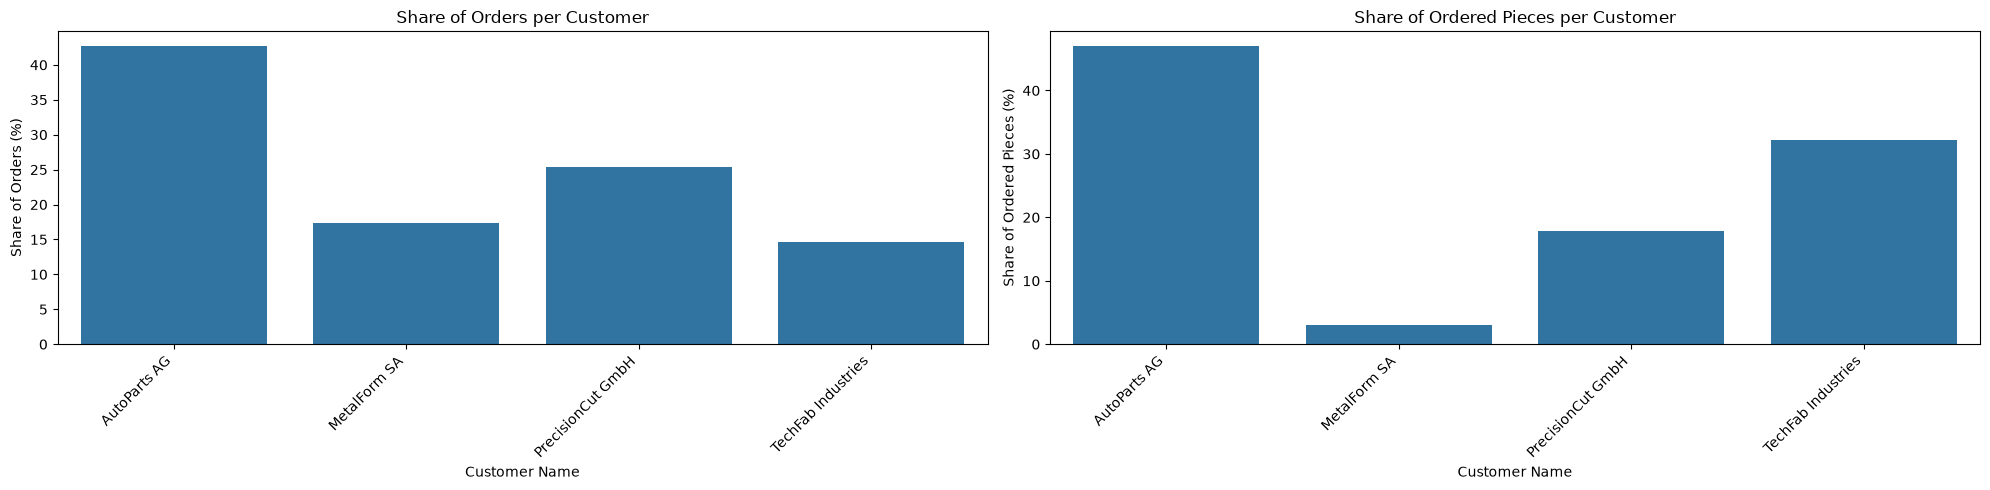

In [3]:
# Create alphabetically sorted DataFrame with customer names and their order counts and shares
customer_df = (
    clean_data['customer_name']
    .dropna()
    .value_counts()
    .rename_axis("customer_name")
    .reset_index(name="number_of_orders")
)
customer_df["share_of_orders"] = customer_df["number_of_orders"] / customer_df["number_of_orders"].sum() * 100
# Add the ordered pieces per customer and their share
customer_df["total_quantity"] = customer_df["customer_name"].map(clean_data.groupby("customer_name")["order_quantity"].sum())
customer_df["share_of_quantity"] = customer_df["total_quantity"] / customer_df["total_quantity"].sum() * 100
customer_df = customer_df.sort_values("customer_name", ascending=True).reset_index(drop=True)
print(customer_df)
print()

# Print the sum and highest number of orders of a customer
print("sum of orders: ", customer_df["number_of_orders"].sum())
print("highest number of orders: ", customer_df["number_of_orders"].max(), "by customer: ", customer_df.loc[customer_df["number_of_orders"].idxmax(), "customer_name"])

# Plot the number, share of orders and share of ordered pieces per customer in bar charts
fig, axes = plt.subplots(1, 2, figsize=(20, 5))

sns.barplot(data=customer_df, x="customer_name", y="share_of_orders", ax=axes[0])
# Formating
axes[0].set_xticks(range(len(customer_df)))
axes[0].set_xticklabels(axes[0].get_xticklabels(), rotation=45, ha="right")
axes[0].set_ylabel("Share of Orders (%)")
axes[0].set_xlabel("Customer Name")
axes[0].set_title("Share of Orders per Customer")



sns.barplot(data=customer_df, x="customer_name", y="share_of_quantity", ax=axes[1])
# Formating
axes[1].set_xticks(range(len(customer_df)))
axes[1].set_xticklabels(axes[1].get_xticklabels(), rotation=45, ha="right")
axes[1].set_ylabel("Share of Ordered Pieces (%)")
axes[1].set_xlabel("Customer Name")
axes[1].set_title("Share of Ordered Pieces per Customer")
# Show plots
plt.tight_layout()
plt.show()

AutoParts AG is the largest customer with 32 orders (42.7 %), followed by PrecisionCut GmbH (19, 25.3 %), MetalForm SA (13, 17.3 %) and TechFab Industries (11, 14.7 %). The two largest customers together account for about two thirds of all orders. Taking order sizes into account changes the picture: AutoParts AG still leads with 47.0 % of the pieces, but here TechFab Industries has the second highes share (32.2 % of pieces from only 14.7 % of orders), while MetalForm SA accounts for 17.3 % of the orders but only 3.0 % of the pieces. 
Conclsuion: TechFab orders few large quantities, MetalForm many small ones.

### 2.2 Customer Branch

Same analysis as for customers, but on the level of branches: number and share of orders per branch, plus the share of ordered pieces. The cross table and the stacked bars show which customer each branch belongs to.

    customer_branch  number_of_orders  share_of_orders  total_quantity  \
0     Berlin Branch                14        18.666667          109550   
1  Frankfurt Branch                13        17.333333           17300   
2    Hamburg Branch                11        14.666667          184000   
3     Munich Branch                18        24.000000          159300   
4  Stuttgart Branch                19        25.333333          102150   

   share_of_quantity  
0          19.142058  
1           3.022890  
2          32.150970  
3          27.835052  
4          17.849030  

sum of orders:  75
highest number of orders:  19 by branch:  Stuttgart Branch

customer_name     AutoParts AG  MetalForm SA  PrecisionCut GmbH  \
customer_branch                                                   
Berlin Branch               14             0                  0   
Frankfurt Branch             0            13                  0   
Hamburg Branch               0             0                  0   
Mu

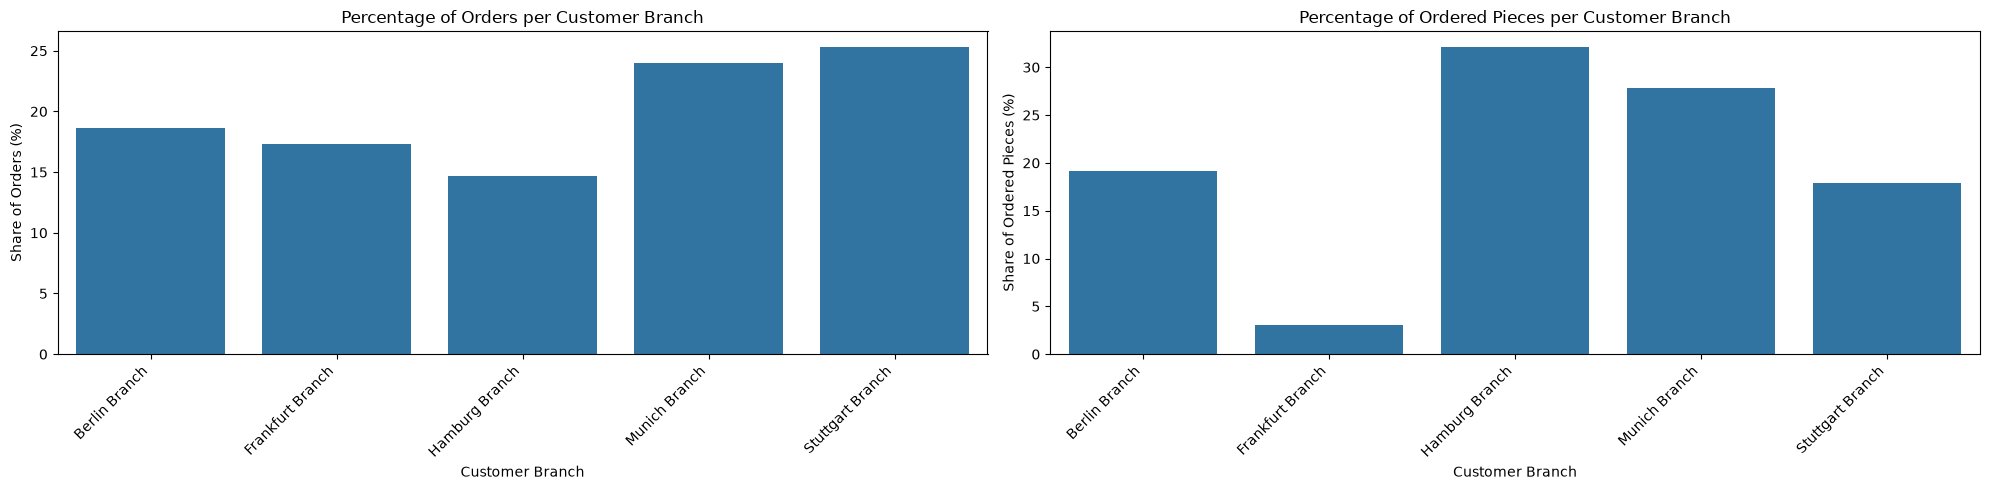

In [4]:
# Create alphabetically sorted DataFrame with customer branches and their order counts and shares
branch_df = (
    clean_data['customer_branch']
    .dropna()
    .value_counts()
    .rename_axis("customer_branch")
    .reset_index(name="number_of_orders")
)
branch_df["share_of_orders"] = branch_df["number_of_orders"] / branch_df["number_of_orders"].sum() * 100
# Add the ordered pieces per branch and their share
branch_df["total_quantity"] = branch_df["customer_branch"].map(clean_data.groupby("customer_branch")["order_quantity"].sum())
branch_df["share_of_quantity"] = branch_df["total_quantity"] / branch_df["total_quantity"].sum() * 100
branch_df = branch_df.sort_values("customer_branch", ascending=True).reset_index(drop=True)
print(branch_df)

# Print the sum and highest number of orders of a customer branch

print()
print("sum of orders: ", branch_df["number_of_orders"].sum())
print("highest number of orders: ", branch_df["number_of_orders"].max(), "by branch: ", branch_df.loc[branch_df["number_of_orders"].idxmax(), "customer_branch"])

# Cross table: which branch belongs to which customer?
branch_customer_table = pd.crosstab(clean_data["customer_branch"], clean_data["customer_name"]).loc[branch_df["customer_branch"]]
print()
print(branch_customer_table)

# Plot the number (stacked by customer), share of orders and share of ordered pieces per branch in bar charts
fig, axes = plt.subplots(1, 2, figsize=(20, 5))

sns.barplot(data=branch_df, x="customer_branch", y="share_of_orders", ax=axes[0])
# Formating
axes[0].set_xticks(range(len(branch_df)))
axes[0].set_xticklabels(axes[0].get_xticklabels(), rotation=45, ha="right")
axes[0].set_ylabel("Share of Orders (%)")
axes[0].set_xlabel("Customer Branch")
axes[0].set_title("Percentage of Orders per Customer Branch")

sns.barplot(data=branch_df, x="customer_branch", y="share_of_quantity", ax=axes[1])
# Formating
axes[1].set_xticks(range(len(branch_df)))
axes[1].set_xticklabels(axes[1].get_xticklabels(), rotation=45, ha="right")
axes[1].set_ylabel("Share of Ordered Pieces (%)")
axes[1].set_xlabel("Customer Branch")
axes[1].set_title("Percentage of Ordered Pieces per Customer Branch")
# Show plots
plt.tight_layout()
plt.show()

Stuttgart (19, 25.3 %) and Munich (18, 24.0 %) place the most orders, Hamburg the fewest (11, 14.7 %). The branch counts are connected to the customer counts: Frankfurt, Hamburg and Stuttgart each belong to exactly one customer, and only AutoParts AG orders from two branches (Munich 18 + Berlin 14 = 32). The branch therefore adds little information beyond the customer, except for the AutoParts AG split (Munich 27.8 % and Berlin 19.1 % of all pieces). The share-of-pieces view is simillar to before: Hamburg (TechFab) has the fewest orders but the largest share of pieces (32.2 %), Frankfurt (MetalForm) only 3.0 %.

### 2.3 Files / Parts

This section checks how often each DXF file appears in the orders. The aim is to find out whether parts are ordered repeatedly or whether every order refers to its own unique part.

In [5]:
# Create DataFrame with file names (sorted in natural order, i.e. Geo (2) before Geo (10)) and their order counts
file_df = (
    clean_data['file_name']
    .dropna()
    .value_counts()
    .rename_axis("file_name")
    .reset_index(name="number_of_orders")
)
file_df = file_df.sort_values("file_name", key=lambda s: s.str.extract(r"\((\d+)\)", expand=False).astype(int)).reset_index(drop=True)
print(file_df)
print()
# Print the sum, highest and lowest number of orders of a file
print("sum of orders: ", file_df["number_of_orders"].sum())
print("highest number of orders: ", file_df["number_of_orders"].max())
print("lowest number of orders: ", file_df["number_of_orders"].min())

       file_name  number_of_orders
0    Geo (1).DXF                 1
1    Geo (2).DXF                 1
2    Geo (3).DXF                 1
3    Geo (4).DXF                 1
4    Geo (5).DXF                 1
..           ...               ...
70  Geo (76).DXF                 1
71  Geo (77).DXF                 1
72  Geo (78).DXF                 1
73  Geo (79).DXF                 1
74  Geo (80).DXF                 1

[75 rows x 2 columns]

sum of orders:  75
highest number of orders:  1
lowest number of orders:  1


Each of the 75 DXF files appears in exactly one order (minimum = maximum = 1). Orders and parts are therefore in a one-to-one relationship, and order-level and part-level statistics are identical. There are no repeat orders, so no conclusions about re-ordering behaviour are possible from this data.

## 3. Numerical Attributes

### 3.1 Order Quantity

Distribution of the ordered quantity per order. The table summarises statistical values while the graphs shows mean, median and mode as well as outliers according to the 1.5 × IQR rule.

In [6]:
# Create a DataFrame with order quantities and their number of appearances
quantity = ( 
    clean_data['order_quantity']
    .dropna()
    .value_counts()
    .rename_axis("order_quantity")
    .reset_index(name="number_of_appearance")
    .sort_values("order_quantity", ascending=True)
    .reset_index(drop=True))

# Print the sum and highest number of appearances of an order quantity
print("sum of appearances: ", quantity["number_of_appearance"].sum())
print("highest number of appearances: ", quantity["number_of_appearance"].max(), ", e.g. by order quantity: ", quantity.loc[quantity["number_of_appearance"].idxmax(), "order_quantity"])
print()

# Calculate quantity statistics
quantities = clean_data["order_quantity"].dropna()
q1, q3 = quantities.quantile(0.25), quantities.quantile(0.75)
iqr = q3 - q1

quantity_statistics = pd.Series({
    "count": quantities.count(),
    "missing": clean_data["order_quantity"].isna().sum(),
    "mean": quantities.mean(),
    "median": quantities.median(),
    "mode": quantities.mode().iloc[0] if not quantities.mode().empty else np.nan,
    "q25": q1,
    "q75": q3,
    "min": quantities.min(),
    "max": quantities.max(),
    "range": quantities.max() - quantities.min(),
    "iqr": iqr,
    "variance": quantities.var(),
    "std": quantities.std(),
    "skewness": quantities.skew(),
    "kurtosis": quantities.kurt(),
    "n_outliers_iqr": ((quantities < q1 - 1.5 * iqr) | (quantities > q3 + 1.5 * iqr)).sum(),
})

print(quantity_statistics.to_frame(name="order quantity"))

sum of appearances:  75
highest number of appearances:  3 , e.g. by order quantity:  4000

                order quantity
count             7.500000e+01
missing           0.000000e+00
mean              7.630667e+03
median            7.650000e+03
mode              4.000000e+03
q25               4.000000e+03
q75               9.050000e+03
min               5.000000e+02
max               1.970000e+04
range             1.920000e+04
iqr               5.050000e+03
variance          2.298425e+07
std               4.794189e+03
skewness          8.629608e-01
kurtosis          7.348472e-01
n_outliers_iqr    6.000000e+00


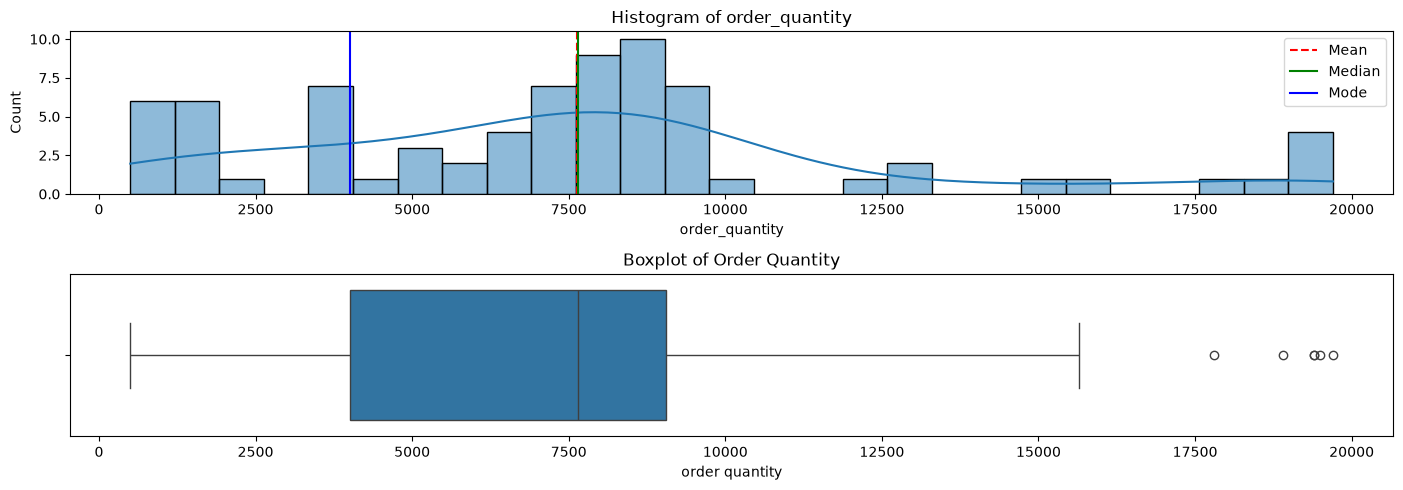

In [7]:
# Visualile the order quantity statistics in a histogram and boxplot
fig, axes = plt.subplots(2, 1, figsize=(14, 5))

sns.histplot(quantities, kde=True, ax=axes[0], binwidth=700)
axes[0].axvline(quantity_statistics["mean"], color="red", linestyle="--", label="Mean")
axes[0].axvline(quantity_statistics["median"], color="green", linestyle="-", label="Median")
axes[0].axvline(quantity_statistics["mode"], color="blue", linestyle="-", label="Mode")
axes[0].set_title("Histogram of order_quantity")
axes[0].legend()


sns.boxplot(x=quantities, ax=axes[1])
axes[1].set_title("Boxplot of Order Quantity")
axes[1].set_xlabel("order quantity")

plt.tight_layout()

Quantities range from 500 to 19,700 pieces (median 7,650, IQR 4,000–9,050). Mean and median almost coincide, and the moderate skewness (0.86) indicates only a slight right tail. The mode (4,000, three times) is weak. Six orders between 17,800 and 19,700 pieces lie above the outlier threshold. 

### 3.2 Bounding Box Width

Distribution of the bounding box width of the parts. The table summarises statistical values while the graphs shows mean, median and mode.

In [8]:
# Calculate width statistics
widths = clean_data["bounding_box_width"].dropna()
q1, q3 = widths.quantile(0.25), widths.quantile(0.75)
iqr = q3 - q1
mean, std = widths.mean(), widths.std()

width_statistics = pd.Series({
    "count": widths.count(),
    "missing": clean_data["bounding_box_width"].isna().sum(),
    "mean": mean,
    "median": widths.median(),
    "q25": q1,
    "q75": q3,
    "min": widths.min(),
    "max": widths.max(),
    "range": widths.max() - widths.min(),
    "iqr": iqr,
    "variance": widths.var(),
    "std": std,
    "skewness": widths.skew(),
    "kurtosis": widths.kurt(),
    "n_outliers_iqr": ((widths < q1 - 1.5 * iqr) | (widths > q3 + 1.5 * iqr)).sum(),
})

print(width_statistics.to_frame(name="bounding box width"))

                bounding box width
count                    75.000000
missing                   0.000000
mean                    678.352528
median                  454.029112
q25                     173.262228
q75                    1150.193570
min                      31.495106
max                    1968.901094
range                  1937.405988
iqr                     976.931343
variance             327612.341046
std                     572.374302
skewness                  0.619176
kurtosis                 -0.845905
n_outliers_iqr            0.000000


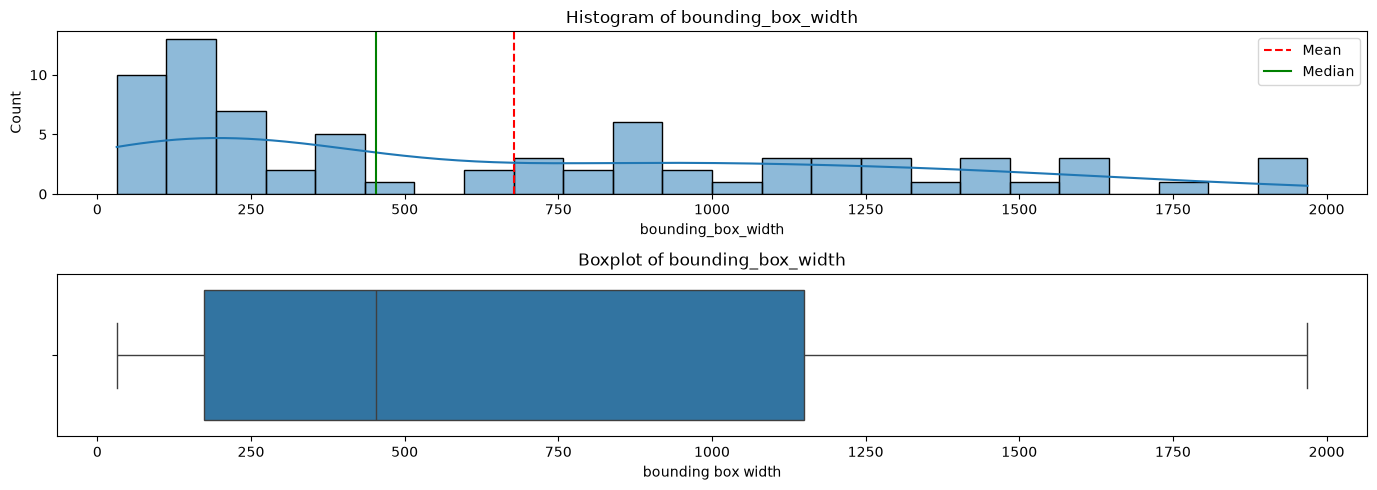

In [9]:
# Visualise the bounding box width statistics in a histogram and box plot
fig, axes = plt.subplots(2, 1, figsize=(14, 5))

sns.histplot(widths, kde=True, ax=axes[0], binwidth=80)
# Formating
axes[0].axvline(width_statistics["mean"], color="red", linestyle="--", label="Mean")
axes[0].axvline(width_statistics["median"], color="green", linestyle="-", label="Median")
axes[0].set_title("Histogram of bounding_box_width")
axes[0].legend()


sns.boxplot(x=widths, ax=axes[1])
# Formating
axes[1].set_title("Boxplot of bounding_box_width")
axes[1].set_xlabel("bounding box width")
plt.tight_layout()

Widths has a very wide range from about 31 to 1,969 (median 454, IQR 173–1,150). The mean (678) is above the median, with moderate right skew (0.62). There are no outliers outside of the whiskers. The width of ordered parts therefore mixes small and very large parts rather evenly.

### 3.3 Bounding Box Height

Distribution of the bounding box height. Statistics and plots follow the same scheme as above.

In [10]:
# Calculate height statistics
heights = clean_data["bounding_box_height"].dropna()
q1, q3 = heights.quantile(0.25), heights.quantile(0.75)
iqr = q3 - q1
mean, std = heights.mean(), heights.std()

height_statistics = pd.Series({
    "count": heights.count(),
    "missing": clean_data["bounding_box_height"].isna().sum(),
    "mean": mean,
    "median": heights.median(),
    "q25": q1,
    "q75": q3,
    "min": heights.min(),
    "max": heights.max(),
    "range": heights.max() - heights.min(),
    "iqr": iqr,
    "variance": heights.var(),
    "std": std,
    "skewness": heights.skew(),
    "kurtosis": heights.kurt(),
    "n_outliers_iqr": ((heights < q1 - 1.5 * iqr) | (heights > q3 + 1.5 * iqr)).sum(),
})

print(height_statistics.to_frame(name="bounding box height"))

                bounding box height
count                     75.000000
missing                    0.000000
mean                     246.674270
median                   131.505377
q25                       70.313000
q75                      312.833986
min                       12.109000
max                     1193.261380
range                   1181.152380
iqr                      242.520986
variance               82949.660114
std                      288.009826
skewness                   2.019651
kurtosis                   3.604705
n_outliers_iqr             7.000000


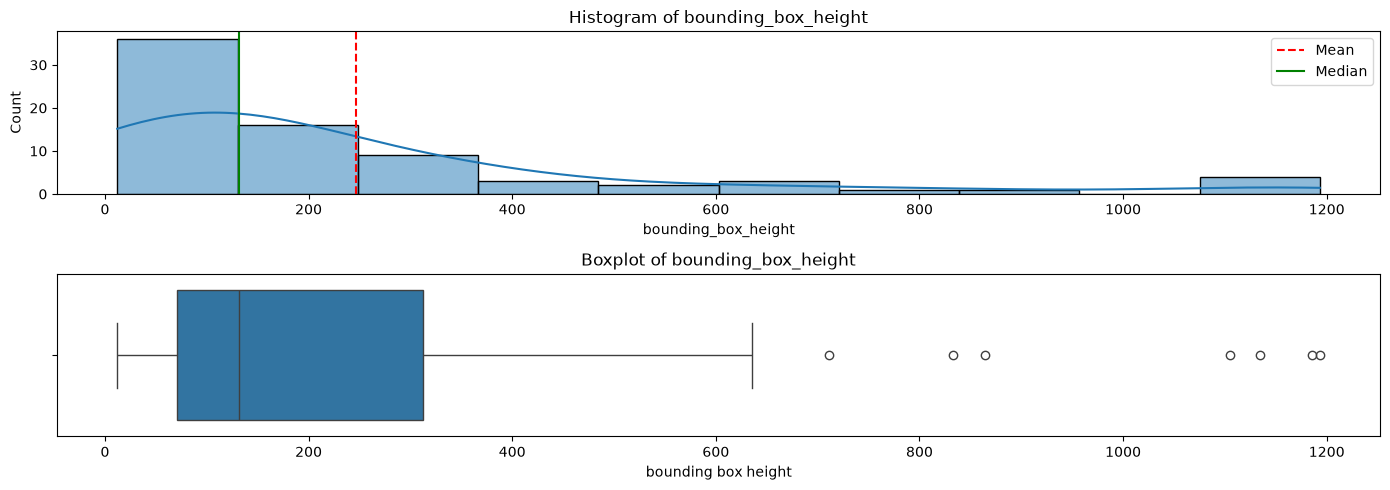

In [11]:
# Visualise the bounding box height statistics in a histogram and box plot
fig, axes = plt.subplots(2, 1, figsize=(14, 5))

sns.histplot(heights, kde=True, ax=axes[0], binwidth=120)
axes[0].axvline(height_statistics["mean"], color="red", linestyle="--", label="Mean")
axes[0].axvline(height_statistics["median"], color="green", linestyle="-", label="Median")
axes[0].set_title("Histogram of bounding_box_height")
axes[0].legend()


sns.boxplot(x=heights, ax=axes[1])
axes[1].set_title("Boxplot of bounding_box_height")
axes[1].set_xlabel("bounding box height")
plt.tight_layout()

Heights are smaller and more concentrated than widths (median 132, IQR 70–313) but have a long right tail: skewness 2.02, kurtosis 3.60, and 7 outliers up to 1,193. The mean (247) is almost twice the median, so the median describes a typical part better.

### 3.4 Cutting Length

Distribution and statistics on the total cutting length of the parts. 

In [12]:
# Calculate cutting length statistics
cutting_lengths = clean_data["cutting_length"].dropna()
q1, q3 = cutting_lengths.quantile(0.25), cutting_lengths.quantile(0.75)
iqr = q3 - q1
mean, std = cutting_lengths.mean(), cutting_lengths.std()

cutting_length_statistics = pd.Series({
    "count": cutting_lengths.count(),
    "missing": clean_data["cutting_length"].isna().sum(),
    "mean": mean,
    "median": cutting_lengths.median(),
    "q25": q1,
    "q75": q3,
    "min": cutting_lengths.min(),
    "max": cutting_lengths.max(),
    "range": cutting_lengths.max() - cutting_lengths.min(),
    "iqr": iqr,
    "variance": cutting_lengths.var(),
    "std": std,
    "skewness": cutting_lengths.skew(),
    "kurtosis": cutting_lengths.kurt(),
    "n_outliers_iqr": ((cutting_lengths < q1 - 1.5 * iqr) | (cutting_lengths > q3 + 1.5 * iqr)).sum(),
})

print(cutting_length_statistics.to_frame(name="cutting length"))

                cutting length
count             7.500000e+01
missing           0.000000e+00
mean              3.046694e+03
median            1.745590e+03
q25               7.752987e+02
q75               3.711433e+03
min               1.009613e+02
max               2.600787e+04
range             2.590691e+04
iqr               2.936134e+03
variance          1.544980e+07
std               3.930623e+03
skewness          3.533509e+00
kurtosis          1.669535e+01
n_outliers_iqr    6.000000e+00


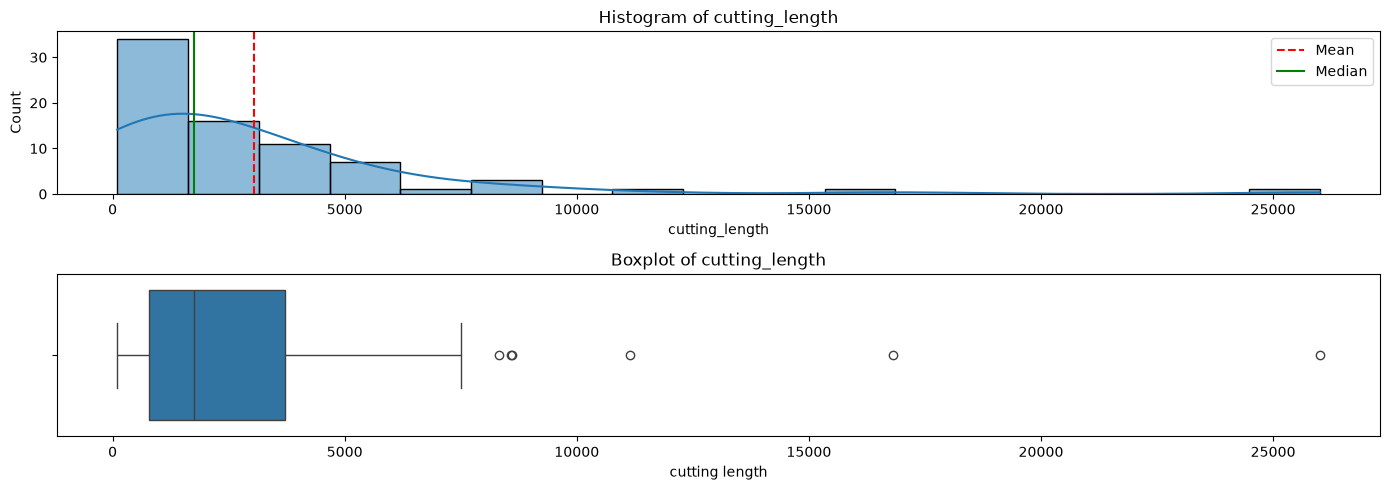

In [13]:
# Visualise the cutting length statistics in a histogram and boxplot
fig, axes = plt.subplots(2, 1, figsize=(14, 5))

sns.histplot(cutting_lengths, kde=True, ax=axes[0], binwidth=1500)
# Formating
axes[0].axvline(cutting_length_statistics["mean"], color="red", linestyle="--", label="Mean")
axes[0].axvline(cutting_length_statistics["median"], color="green", linestyle="-", label="Median")
axes[0].set_title("Histogram of cutting_length")
axes[0].legend()


sns.boxplot(x=cutting_lengths, ax=axes[1])
# Formating
axes[1].set_title("Boxplot of cutting_length")
axes[1].set_xlabel("cutting length")
plt.tight_layout()

Cutting length is the strongly skewed (skewness 3.53, kurtosis 16.7). The median is 1,746 against a mean of 3,047, and the range runs from 101 to 26,008. The maximum ist about 8.5 times bigger than the mean. Six outliers lie to the right. 

### 3.5 Bounding Box Area

Distribution of the bounding box area. It is derived directly from the bounding box lenth and width (area = width × height) and is therefore not independent, but it gives a measure of the part size.

In [14]:
# Calculate bounding box area statistics
bounding_box_areas = clean_data["bounding_box_area"].dropna()
q1, q3 = bounding_box_areas.quantile(0.25), bounding_box_areas.quantile(0.75)
iqr = q3 - q1
mean, std = bounding_box_areas.mean(), bounding_box_areas.std()

bounding_box_area_statistics = pd.Series({
    "count": bounding_box_areas.count(),
    "missing": clean_data["bounding_box_area"].isna().sum(),
    "mean": mean,
    "median": bounding_box_areas.median(),
    "q25": q1,
    "q75": q3,
    "min": bounding_box_areas.min(),
    "max": bounding_box_areas.max(),
    "range": bounding_box_areas.max() - bounding_box_areas.min(),
    "iqr": iqr,
    "variance": bounding_box_areas.var(),
    "std": std,
    "skewness": bounding_box_areas.skew(),
    "kurtosis": bounding_box_areas.kurt(),
    "n_outliers_iqr": ((bounding_box_areas < q1 - 1.5 * iqr) | (bounding_box_areas > q3 + 1.5 * iqr)).sum(),
})

print(bounding_box_area_statistics.to_frame(name="bounding box area"))

                bounding box area
count                7.500000e+01
missing              0.000000e+00
mean                 2.666915e+05
median               6.546316e+04
q25                  1.505401e+04
q75                  2.846438e+05
min                  3.813742e+02
max                  2.209629e+06
range                2.209248e+06
iqr                  2.695898e+05
variance             2.373305e+11
std                  4.871658e+05
skewness             2.744919e+00
kurtosis             7.210347e+00
n_outliers_iqr       7.000000e+00


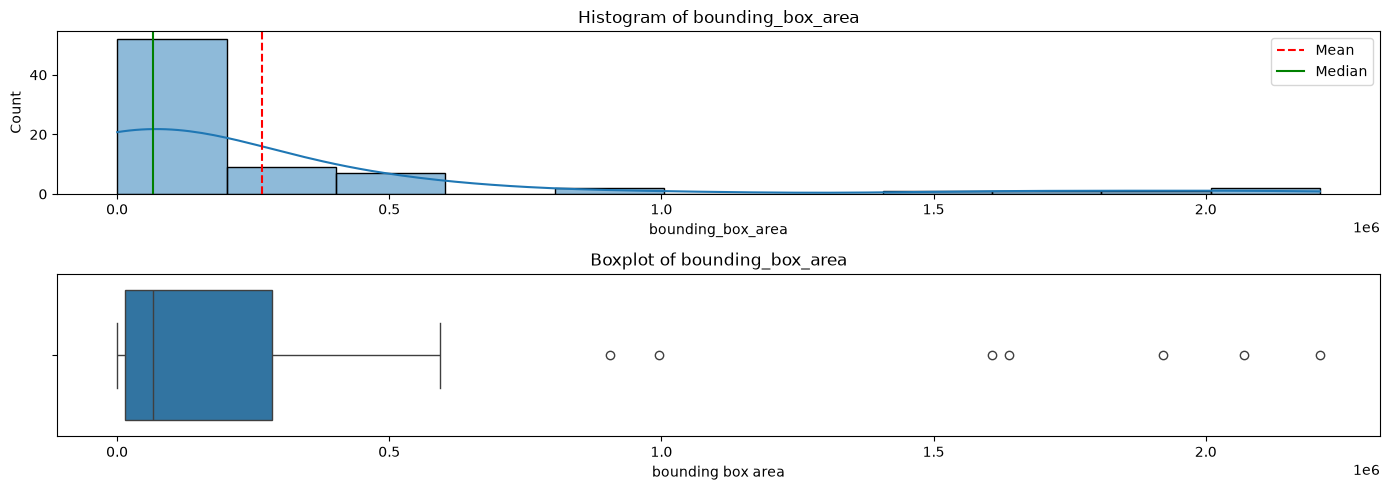

In [15]:
# Visualise the bounding box area statistics in a histogram and boxplot
fig, axes = plt.subplots(2, 1, figsize=(14, 5))

sns.histplot(bounding_box_areas, kde=True, ax=axes[0], binwidth=200000)
# Formating
axes[0].axvline(bounding_box_area_statistics["mean"], color="red", linestyle="--", label="Mean")
axes[0].axvline(bounding_box_area_statistics["median"], color="green", linestyle="-", label="Median")
axes[0].set_title("Histogram of bounding_box_area")
axes[0].legend()


sns.boxplot(x=bounding_box_areas, ax=axes[1])
# Formating
axes[1].set_title("Boxplot of bounding_box_area")
axes[1].set_xlabel("bounding box area")
plt.tight_layout()

Bounding box areas span imensly ( 381 to 2.2 million), with a median of ≈ 65,000 and a mean of ≈ 267,000. The distribution is strongly right-skewed (2.74, kurtosis 7.2), and 7 parts are flagged as outliers to the right. As area is fully determined by width and height, it is not an independent information.

### 3.6 Number of Holes

Distribution of the number of holes per part. As a count variable it is analysed as a frequency table and with the same descriptive statistics as the continuous attributes.

In [16]:
# Create a Data Frame with number of holes and their number of appearances
hole = ( 
    clean_data['num_holes']
    .dropna()
    .value_counts()
    .rename_axis("num_holes")
    .reset_index(name="number_of_appearance")
    .sort_values("num_holes", ascending=True)
    .reset_index(drop=True))

# Print the frequency table, the sum and highest number of appearances of a number of holes
print(hole.T.to_string(header=False))
print()
print("sum of appearances: ", hole["number_of_appearance"].sum())
print("highest number of appearances: ", hole["number_of_appearance"].max(), ", e.g. by number of holes: ", hole.loc[hole["number_of_appearance"].idxmax(), "num_holes"])
# Share of parts without holes
parts_without_holes = (clean_data["num_holes"] == 0).sum()
print(f"parts without holes: {parts_without_holes} of {len(clean_data)} ({parts_without_holes / len(clean_data) * 100:.1f} %)")
print()

# Calculate number of holes statistics
num_holes = clean_data["num_holes"].dropna()
q1, q3 = num_holes.quantile(0.25), num_holes.quantile(0.75)
iqr = q3 - q1
mean, std = num_holes.mean(), num_holes.std()   

num_holes_statistics = pd.Series({
    "count": num_holes.count(),
    "missing": clean_data["num_holes"].isna().sum(),
    "mean": mean,
    "median": num_holes.median(),
    "mode": num_holes.mode().iloc[0] if not num_holes.mode().empty else np.nan,
    "q25": q1,
    "q75": q3,
    "min": num_holes.min(),
    "max": num_holes.max(),
    "range": num_holes.max() - num_holes.min(),
    "iqr": iqr,
    "variance": num_holes.var(),
    "std": std,
    "skewness": num_holes.skew(),
    "kurtosis": num_holes.kurt(),
    "n_outliers_iqr": ((num_holes < q1 - 1.5 * iqr) | (num_holes > q3 + 1.5 * iqr)).sum(),
})

print(num_holes_statistics.to_frame(name="number of holes"))

num_holes              0  1  2  3  4  5  6  7  9  10  11  13  14  15  16  19  21  26  27  31  52  219
number_of_appearance  19  2  8  5  6  3  3  9  2   2   3   1   1   3   1   1   1   1   1   1   1    1

sum of appearances:  75
highest number of appearances:  19 , e.g. by number of holes:  0
parts without holes: 19 of 75 (25.3 %)

                number of holes
count                 75.000000
missing                0.000000
mean                   9.426667
median                 4.000000
mode                   0.000000
q25                    0.500000
q75                    9.000000
min                    0.000000
max                  219.000000
range                219.000000
iqr                    8.500000
variance             675.518198
std                   25.990733
skewness               7.339981
kurtosis              58.952164
n_outliers_iqr         5.000000


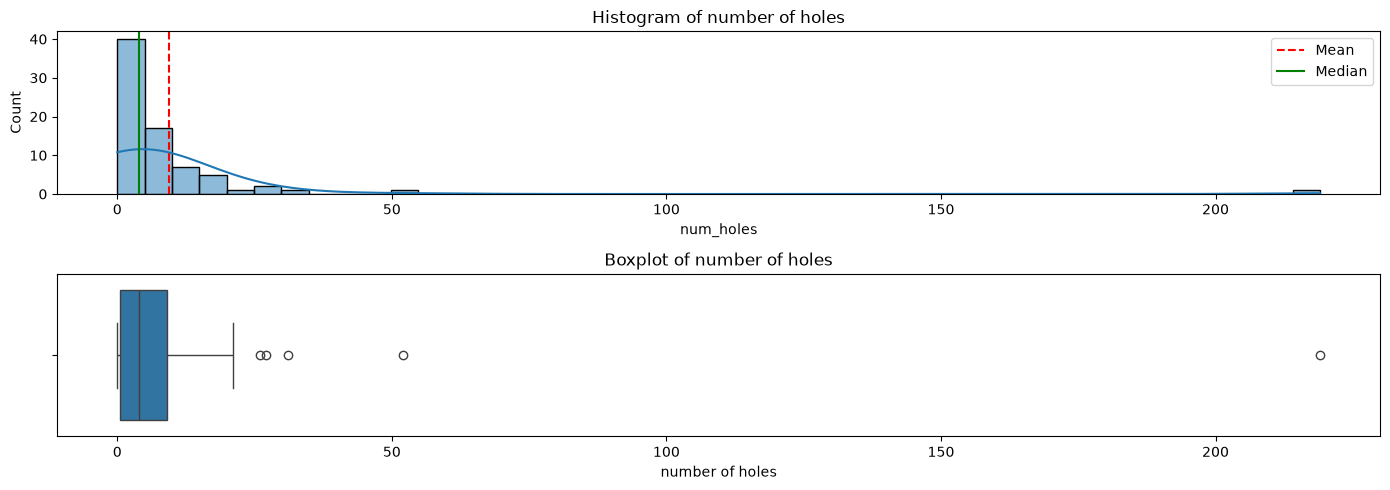

In [17]:
# Visualise the number of holes statistics in a histogram and boxplot
fig, axes = plt.subplots(2, 1, figsize=(14, 5))

sns.histplot(num_holes, kde=True, ax=axes[0], binwidth=5)
# Formating
axes[0].axvline(num_holes_statistics["mean"], color="red", linestyle="--", label="Mean")
axes[0].axvline(num_holes_statistics["median"], color="green", linestyle="-", label="Median")
axes[0].set_title("Histogram of number of holes")
axes[0].legend()


sns.boxplot(x=num_holes, ax=axes[1])
# Formating
axes[1].set_title("Boxplot of number of holes")
axes[1].set_xlabel("number of holes")
plt.tight_layout()

Holes are extremely right-skewed (skewness 7.34, kurtosis 59). The most frequent value is 0 (19 of 75 parts, ≈ 25 %), the median is 4, and the mean (9.4) is inflated by a few extreme outliers to the right. Five outliers are detected. They influence variance, skewness and kurtosis, so Median and IQR are more representatives of the distribution here.

### 3.7 Rectangularity Ratio

Distribution of the rectangularity ratio, which describes how well a part fills its bounding box (1 = perfect rectangle, values close to 0 = very sparse shape). The ratio is bounded to (0, 1] since it is the percentage of bounding box area filled by the part. 

In [18]:
# Calculate rectangularity ratio statistics
rectangularity_ratio_stats = clean_data["rectangularity"].dropna()
q1, q3 = rectangularity_ratio_stats.quantile(0.25), rectangularity_ratio_stats.quantile(0.75)
iqr = q3 - q1
mean, std = rectangularity_ratio_stats.mean(), rectangularity_ratio_stats.std()   

rectangularity_ratio_statistics = pd.Series({
    "count": rectangularity_ratio_stats.count(),
    "missing": clean_data["rectangularity"].isna().sum(),
    "mean": mean,
    "median": rectangularity_ratio_stats.median(),
    "q25": q1,
    "q75": q3,
    "min": rectangularity_ratio_stats.min(),
    "max": rectangularity_ratio_stats.max(),
    "range": rectangularity_ratio_stats.max() - rectangularity_ratio_stats.min(),
    "iqr": iqr,
    "variance": rectangularity_ratio_stats.var(),
    "std": std,
    "skewness": rectangularity_ratio_stats.skew(),
    "kurtosis": rectangularity_ratio_stats.kurt(),
    "n_outliers_iqr": ((rectangularity_ratio_stats < q1 - 1.5 * iqr) | (rectangularity_ratio_stats > q3 + 1.5 * iqr)).sum(),
})

print(rectangularity_ratio_statistics.to_frame(name="rectangularity ratio"))

                rectangularity ratio
count                      75.000000
missing                     0.000000
mean                        0.687467
median                      0.724271
q25                         0.544393
q75                         0.882518
min                         0.082199
max                         0.999999
range                       0.917800
iqr                         0.338125
variance                    0.058096
std                         0.241032
skewness                   -0.713761
kurtosis                   -0.199174
n_outliers_iqr              0.000000


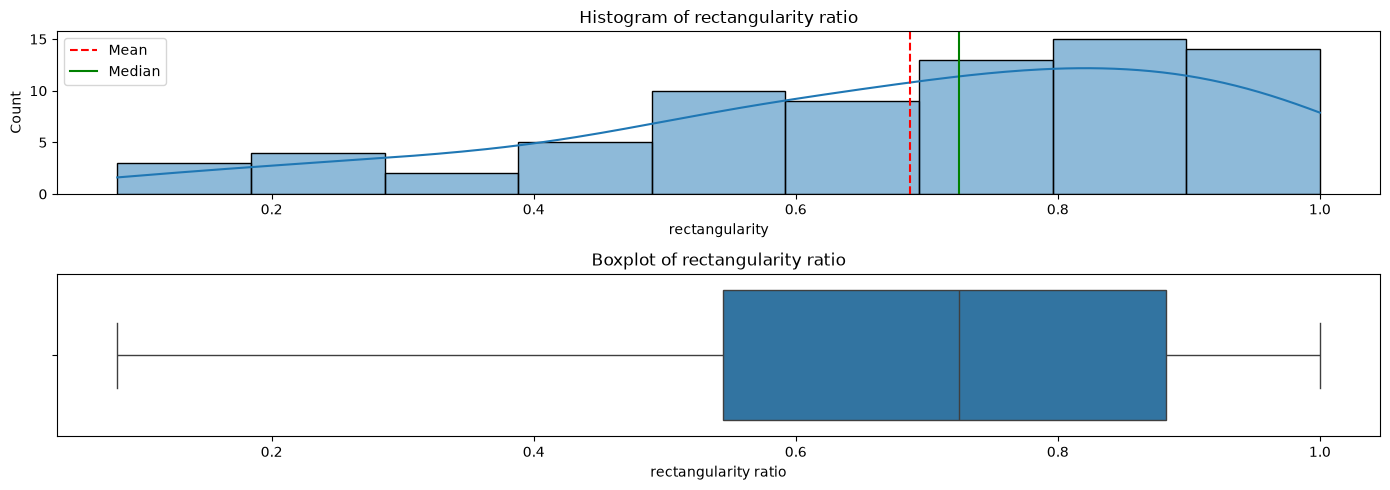

In [19]:
# Visualise the rectangularity ratio statistics in a histogram and boxplot
fig, axes = plt.subplots(2, 1, figsize=(14, 5))

sns.histplot(rectangularity_ratio_stats, kde=True, ax=axes[0], binwidth=0.1)
# Formating
axes[0].axvline(rectangularity_ratio_statistics["mean"], color="red", linestyle="--", label="Mean")
axes[0].axvline(rectangularity_ratio_statistics["median"], color="green", linestyle="-", label="Median")
axes[0].set_title("Histogram of rectangularity ratio")
axes[0].legend()


sns.boxplot(x=rectangularity_ratio_stats, ax=axes[1])
# Formating
axes[1].set_title("Boxplot of rectangularity ratio")
axes[1].set_xlabel("rectangularity ratio")
plt.tight_layout()

The recengularity ratios is lie between 0.082 and 1 (median 0.72, IQR  0.34) within the expected range (0, 1]. The distribution in left skewed (skewness -0.713761, kurtosis -0.199174), the majority of parts fills the bounding box quite well. There are no outliers detected.

## 4. Summary

Key findings of the univariate analysis and open points for the next steps.

- **Orders:** 75 orders, each a unique part; AutoParts AG is the largest customer (≈ 43 % of orders)
- **Size attributes:** width, height, area and cutting length are right-skewed. Median and IQR are more representative than the mean, and log transformation should be considered
- **Customer structure:** MetalForm SA orders many small series, TechFab Industries orders few but large series
- **Number of holes:** many parts with zero holes, with one extreme part with 219 holes
- **Dependency:** area is derived from width × height